# Cleanup old processes

In [3]:
!pkill -u "$USER" -f '^clingcon '
!ps -aux | grep clingcon

unknown   328191 83.3  0.0  10352  3600 pts/4    Ss+  18:31   0:00 /bin/bash -c ps -aux | grep clingcon
unknown   328193  0.0  0.0   9692  2304 pts/4    S+   18:31   0:00 grep clingcon


# OLD: Run clingcon on instance with timeout, write result to result.out

In [ ]:
import time, os

timeMax = "86400"
instanceName = "green_circuit.lp"
coreCount = "32"
use_tmux = True

outfile = "i_" + instanceName + "-t_" + timeMax + "-cpu_" + coreCount + "-" + time.strftime("%Y%m%d_%H%M%S") + ".log"
print(outfile)

instancePath = f"instances/{instanceName}"

if use_tmux:
    sessionName = "asp"
    !tmux new-session -d -s {sessionName} "bash -lc 'echo \"================ INSTANCE BEGIN ================\" > logs/{outfile}; echo \"File: {instancePath}\" >> logs/{outfile}; echo \"------------------------------------------------\" >> logs/{outfile}; cat {instancePath} >> logs/{outfile}; echo >> logs/{outfile}; echo \"================ CLINGCON OUTPUT ================\" >> logs/{outfile}; systemd-run --user --scope -p MemoryMax=128G -p MemoryHigh=120G -p MemorySwapMax=0 clingcon model2.lp heuristic.lp game.lp {instancePath} --opt-mode=ignore -n 1 --quiet=1 -t {coreCount} --time {timeMax} >> logs/{outfile} 2>&1'"
    print(f"Started tmux session: {sessionName}")
    print(f"Attach with: tmux attach -d -t {sessionName}")
    !while tmux has-session -t {sessionName} 2>/dev/null; do sleep 5; done; echo finished
else:
    !bash -lc 'echo "================ INSTANCE BEGIN ================" > logs/{outfile}; echo "File: {instancePath}" >> logs/{outfile}; echo "------------------------------------------------" >> logs/{outfile}; cat {instancePath} >> logs/{outfile}; echo >> logs/{outfile}; echo "================ CLINGCON OUTPUT ================" >> logs/{outfile}; systemd-run --user --scope -p MemoryMax=128G -p MemoryHigh=120G -p MemorySwapMax=0 clingcon model2.lp heuristic.lp game.lp {instancePath} --opt-mode=ignore -n 1 --quiet=1 -t {coreCount} --time {timeMax} >> logs/{outfile} 2>&1'

# NEW: 

20260313_213113_red_circuit.lp_solve_-t_86400-cpu_32.log
logs/20260313_213113_red_circuit.lp_dependency_graph.log
logs/20260313_213113_red_circuit.lp_dependency_graph_encoding.lp


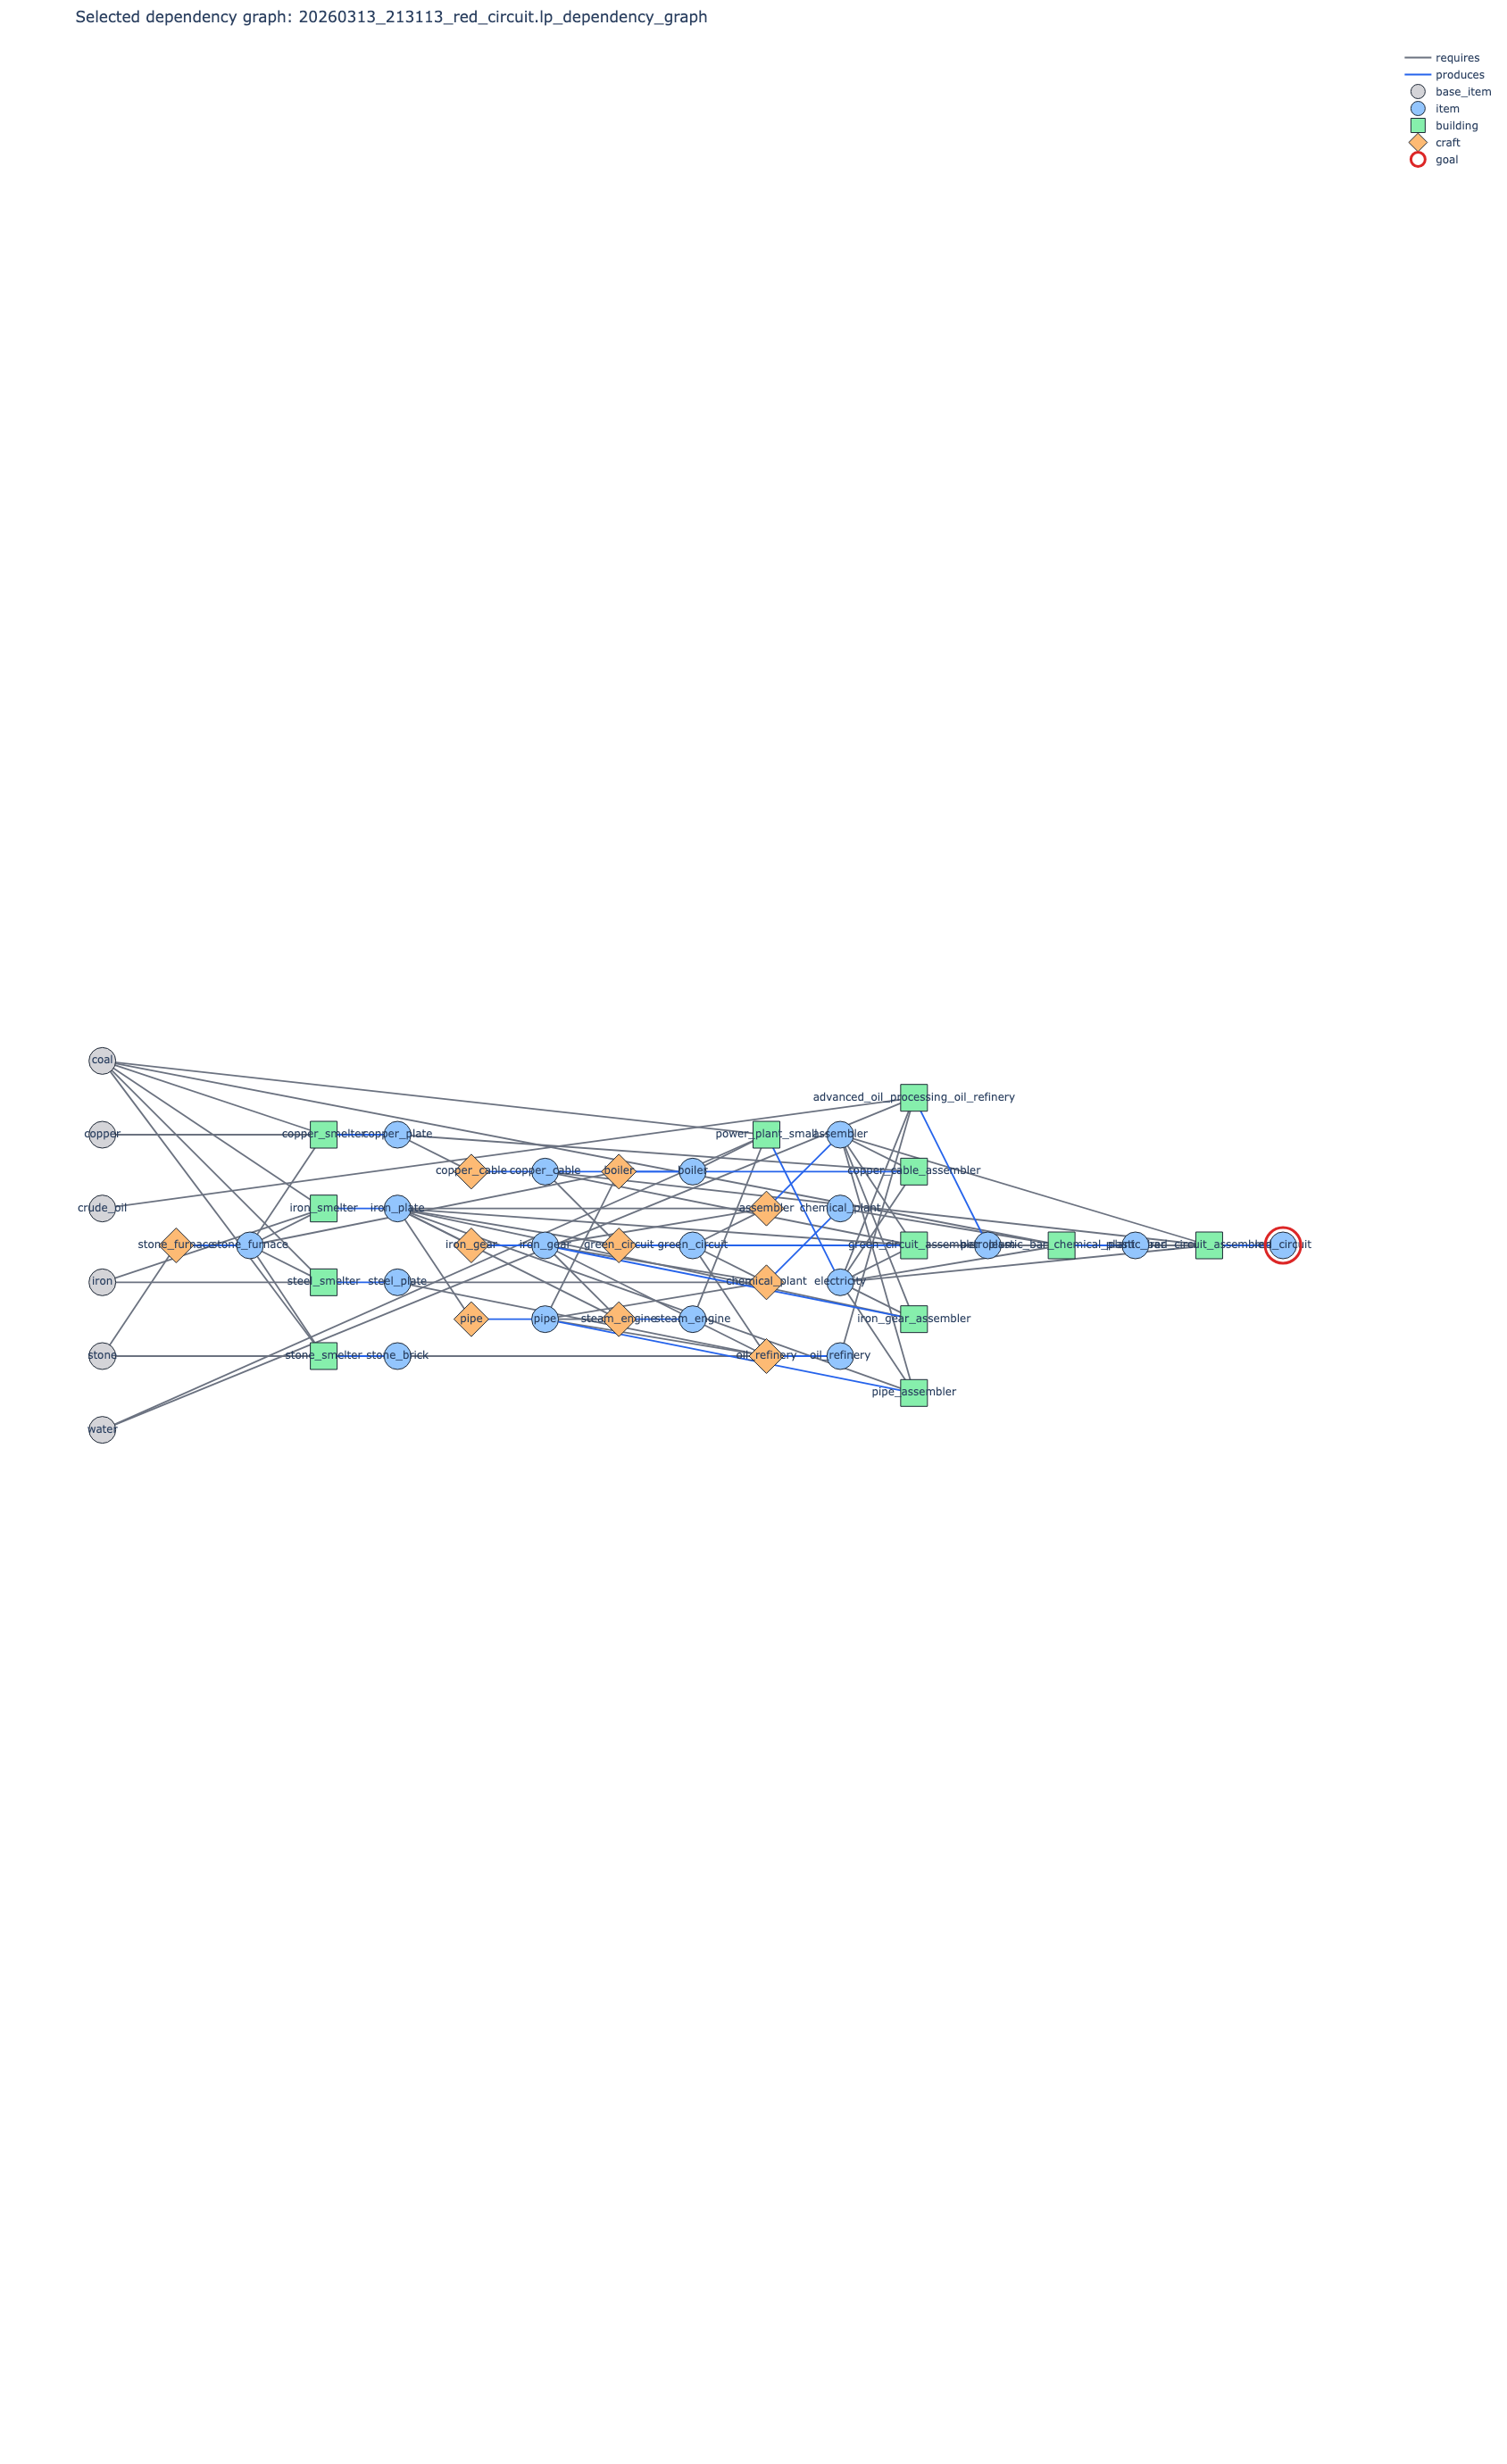

Started tmux session: asp_red_circuit_20260313_213113
Attach with: tmux attach -d -t asp_red_circuit_20260313_213113


In [ ]:
import time
from pathlib import Path

from graph_plotly_viewer import GoalDependencyViewer
from graph_tools import graph_log_to_lp, run_graph_phase

timeMax = "86400"
instanceName = "red_circuit.lp"
coreCount = "32"

timestamp = time.strftime("%Y%m%d_%H%M%S")
instancePath = Path("instances") / instanceName
instanceStem = instancePath.stem
graphLogPath = Path("logs") / f"{timestamp}_{instanceName}_dependency_graph.log"
hintPath = Path("logs") / f"{timestamp}_{instanceName}_dependency_graph_encoding.lp"
outfile = f"{timestamp}_{instanceName}_solve_-t_{timeMax}-cpu_{coreCount}.log"
sessionName = f"asp_{instanceStem}_{timestamp}"

Path("logs").mkdir(exist_ok=True)

# Phase 1: solve the global graph and minimal grounded subgraph for the full instance.
run_graph_phase(instancePath, graphLogPath)
graph_log_to_lp(graphLogPath, hintPath)

print(outfile)
print(graphLogPath)
print(hintPath)

# Visualize the minimal subgraph with depth measured from base resources.
GoalDependencyViewer.from_log(graphLogPath).show()

# Phase 2: run the full model with the generated graph-depth hints.
instanceArg = str(instancePath)
hintArg = str(hintPath)

!tmux new-session -d -s {sessionName} "bash -lc 'echo \"================ INSTANCE BEGIN ================\" > logs/{outfile}; echo \"File: {instanceArg}\" >> logs/{outfile}; echo \"Hints: {hintArg}\" >> logs/{outfile}; echo \"Graph log: {graphLogPath}\" >> logs/{outfile}; echo \"------------------------------------------------\" >> logs/{outfile}; cat {instanceArg} >> logs/{outfile}; echo >> logs/{outfile}; echo \"================ CLINGCON OUTPUT ================\" >> logs/{outfile}; systemd-run --user --scope -p MemoryMax=128G -p MemoryHigh=120G -p MemorySwapMax=0 clingcon model2.lp game.lp heuristic.lp {instanceArg} {hintArg} --opt-mode=ignore -n 1 --quiet=1 -t {coreCount} --time {timeMax} >> logs/{outfile} 2>&1'"
print(f"Started tmux session: {sessionName}")
print(f"Attach with: tmux attach -d -t {sessionName}")
!while tmux has-session -t {sessionName} 2>/dev/null; do sleep 5; done; echo finished


In [ ]:
from clingcon_plotly_viewer import ClingconAssignmentViewer

viewer = ClingconAssignmentViewer.from_log("logs/i_red_circuit.lp-t_86400-cpu_64-20260310_184714.log")
#viewer = ClingconAssignmentViewer.from_log("logs/" + outfile)
ui = viewer.interactive_explorer_widget(cols=4, show_zeros_3d=True)
display(ui)